Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.analysis.cytosol import platereader as pr

# Set up plotting
pr.plot_setup()

## Load Data

In [2]:
# Specify file paths
data_file = "20260609-151420-cytation5-pure-timecourse-gfp-biotek-cdk.txt"
platemap_file = "20260609-GFP-ssrA and ClpX.csv"


# Load data
data, platemap = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek-cdk"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
data.head()

,Time,Temperature,Well,Data,Row,Column,Read,Plate,Clock Time,Reader,Name
0,0 days 00:00:10,37.00,A1,461,A,1,GFP-Gext,Plate 1,2026-06-09 15:47:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pu...
1,0 days 00:05:10,37.00,A1,430,A,1,GFP-Gext,Plate 1,2026-06-09 15:52:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pu...
2,0 days 00:10:10,37.00,A1,1248,A,1,GFP-Gext,Plate 1,2026-06-09 15:57:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pu...
3,0 days 00:15:10,37.00,A1,2978,A,1,GFP-Gext,Plate 1,2026-06-09 16:02:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pu...
4,0 days 00:20:10,37.00,A1,4760,A,1,GFP-Gext,Plate 1,2026-06-09 16:07:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pu...


## Plot Raw Curves

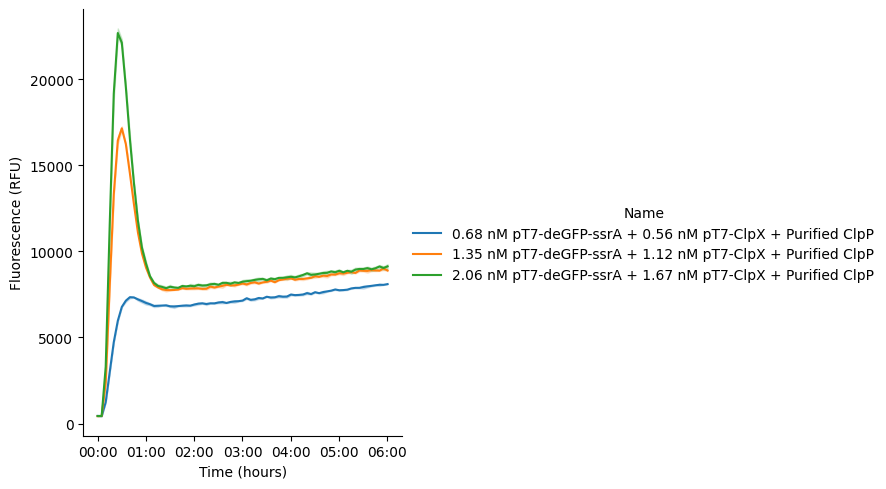

In [3]:
#| label: 20260609-gfp-clpx
g = pr.plot_curves(data=data)

## Normalize Data

In [4]:
data = pr.normalize_data_to_controls(data, ctrl_name = '10 uM HPTS')

Control name '10 uM HPTS' not found in data. No normalization applied.


Now replot your curves to see them normalized

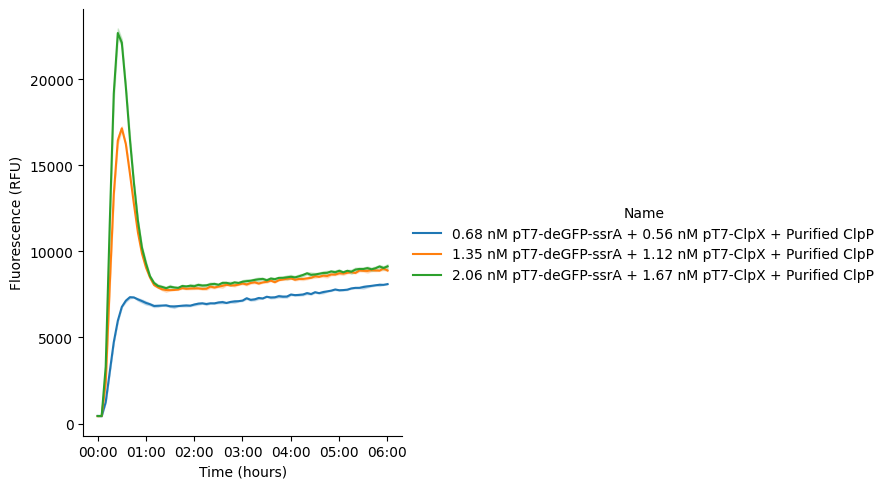

In [5]:
g = pr.plot_curves(data=data)

## Kinetic Analysis
**Metrics extracted:**

  - **Vmax** (`Velocity Max`): Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level and time to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit

In [6]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = pr.kinetic_analysis(
    data=data,
    group_by=['Well','Name'],  # Group by experimental condition
)

kinetics.head()

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


Velocity  \
                                                                             Time   
Well Name                                                                           
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:16:23.397840220   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:00:52.066021050   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 0 days 00:06:33.120746179   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:16:17.009900313   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:02:25.822476643   

                                                                            \
                                                           Data        Max   
Well Name                                                                    
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 3356.05   24017.59   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 4446.82 2049350.50   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 5443.38  619753.80   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 3311.36   24435.44   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 4416.74 1724290.94   

                                                                              Lag  \
                                                                             Time   
Well Name                                                                           
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:08:00.359217455   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:00:44.254496739   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 0 days 00:06:01.501462519   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:08:09.157651983   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:02:16.601140129   

                                                                 \
                                                           Data   
Well Name                                                         
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur...  827.09   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 1473.59   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 1652.94   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur...  818.81   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 1491.49   

                                                                     Steady State  \
                                                                             Time   
Well Name                                                                           
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:28:43.981104342   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:01:03.566299310   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 0 days 00:07:19.671271564   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur... 0 days 00:28:15.235487882   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur... 0 days 00:02:39.398307036   

                                                                  \
                                                            Data   
Well Name                                                          
A1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur...  6376.49   
A2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur...  8448.96   
A3   2.06 nM pT7-deGFP-ssrA + 1.67 nM pT7-ClpX + Pur... 10342.42   
B1   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + Pur...  6291.58   
B2   1.35 nM pT7-deGFP-ssrA + 1.12 nM pT7-ClpX + Pur...  8391.81   

                                                                                                       Fit  \
                                                                                                    params   
Well Name                                                                                              

## Visualize Fits on Individual Wells

`Type` column not found in data. All data will be used for kinetic analysis.


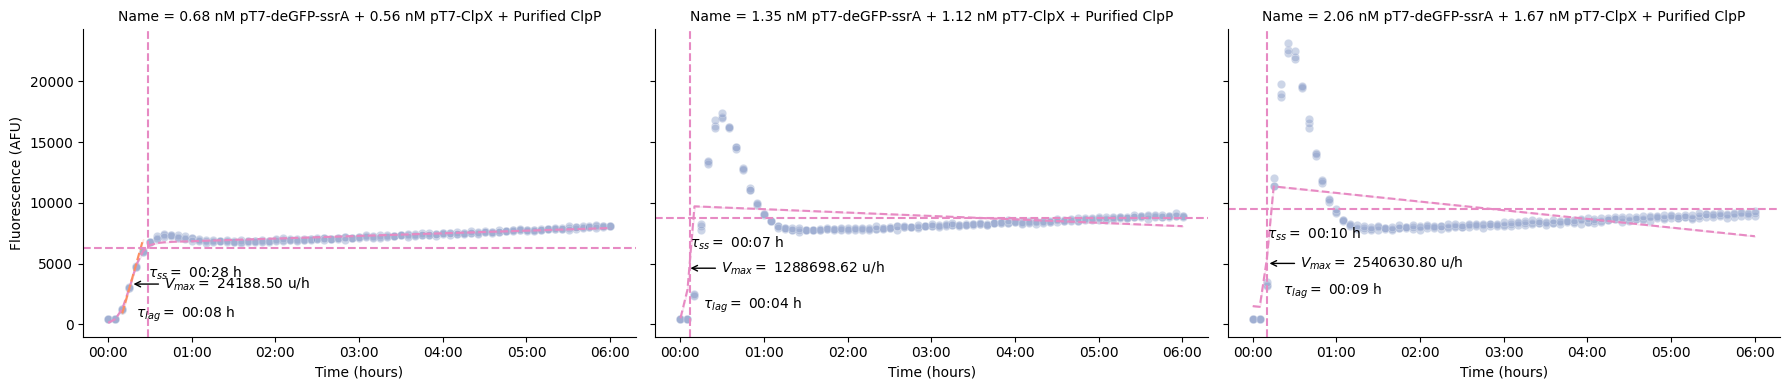

In [7]:
# Plot kinetic fits 
g = pr.plot_kinetics(data, kinetics=kinetics)

## Summary Plots

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


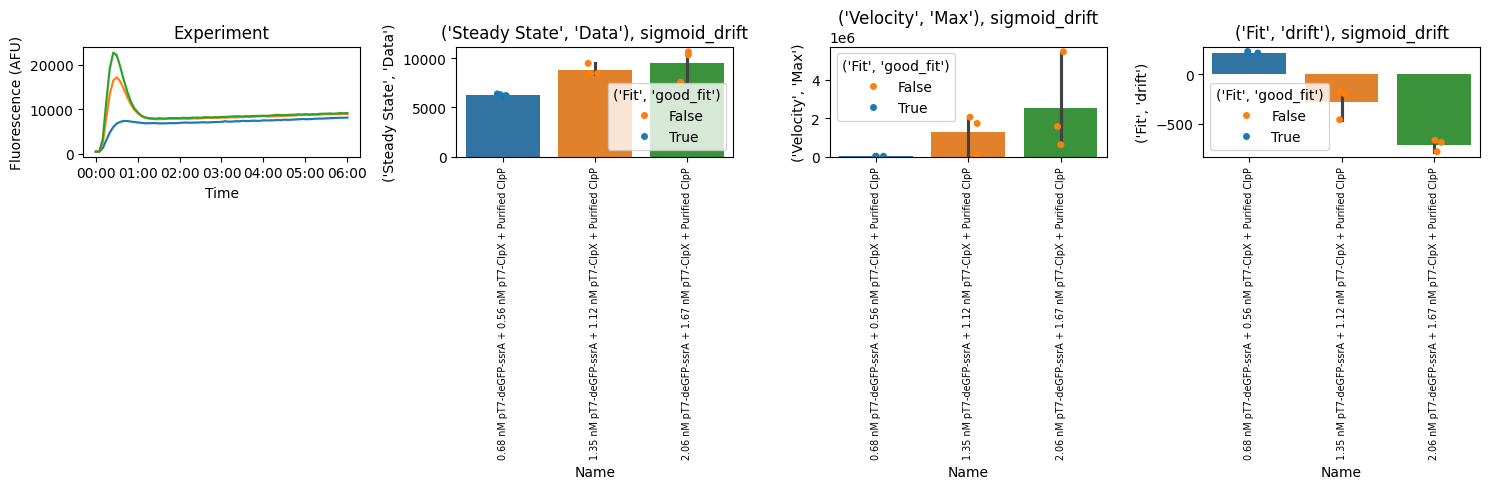

In [8]:
g = pr.plot_summary(data)
# g.savefig("summary.png", dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants